# PathSnap preprocessing: flags, labelling, candidates, features (stage 1: sections 4.1 - 4.3)

Builds the model-ready candidate-ranking table. **No model is trained here.**
Formulation: per GPS point -> candidate arcs -> features per (point, candidate) -> label 1 if the candidate is the
reference arc. Networks are **per trip**, so `arc_id` is local and never a global class.

Partitions used: **train (80 trips)** and **student_test (10 trips)**. The evaluator partition is never opened.
Index spaces (never joined by row number): `gps_row`, `node_id` (local), `arc_id` (local), `route_pos`.

This notebook covers 4.1 (loader), 4.2 (point flags), 4.3 (route-constrained labelling). Sections 4.4+ follow after review.
Thresholds come from the EDA `CONFIG` cell (the EDA's `outputs/preprocessing_config.json` is git-ignored and is not in the repo).

## 4.1 Setup, config and per-trip loader

In [1]:
"""Setup: imports, paths, config. Restart-and-Run-All safe."""
import sys, time, json, random
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, folium
from pyproj import Transformer

HERE = Path.cwd()
sys.path.insert(0, str(HERE))                       # make pathsnap_prep importable from the notebook folder
import pathsnap_prep as P

CONFIG = dict(P.CONFIG)                              # every threshold + reason is documented in pathsnap_prep.CONFIG
random.seed(CONFIG["seed"]); np.random.seed(CONFIG["seed"])
ROOT = P.find_repo_root(HERE)                        # repository root (folder holding Dataset/)
DATA = ROOT / "Dataset"
CACHE = HERE / "cache"                               # per-trip projected arrays (git-ignored)
OUTD = ROOT / "data_preprocessing" / "cleaned_data"  # cleaned/processed tables are written here
VAL = OUTD / "validation"; VAL.mkdir(parents=True, exist_ok=True)
# Only train and student_test are listed; the evaluator partition is never touched.
SPLITS = {"train": P.list_trips(DATA, "train"), "student_test": P.list_trips(DATA, "student_test")}
print({k: len(v) for k, v in SPLITS.items()}, "| config keys:", len(CONFIG))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

{'train': 80, 'student_test': 10} | config keys: 18


In [2]:
"""Load every trip once (projects to its own UTM zone, derives arc geometry, caches to disk). No route is read."""
trips = {}                                           # (split, trip_id) -> Trip
t0 = time.time(); inv = []
for split, ids in SPLITS.items():
    for tid in ids:
        tr = P.load_trip(DATA, split, tid, CACHE)
        P.assert_index_spaces(tr)                    # index-space assertions
        # projection round trip: UTM -> lon/lat must reproduce the raw GPS to < 1e-6 deg (~0.1 m)
        back = Transformer.from_crs(tr.epsg, 4326, always_xy=True).transform(tr.gps_xy[:, 0], tr.gps_xy[:, 1])
        assert np.abs(back[0] - tr.gps_lonlat[:, 0]).max() < 1e-6 and np.abs(back[1] - tr.gps_lonlat[:, 1]).max() < 1e-6
        trips[(split, tid)] = tr
        inv.append(dict(split=split, trip_id=tid, epsg=tr.epsg, n_gps=tr.n_gps, n_nodes=len(tr.node_xy), n_arcs=tr.n_arcs,
                        median_arc_len_m=float(np.median(tr.arc_len)), zero_len_arcs=int((tr.arc_len == 0).sum()),
                        one_way_arc_share=float(1 - tr.arc_has_reverse.mean())))
inv = pd.DataFrame(inv); inv.to_csv(VAL / "trip_inventory.csv", index=False)
print("loaded %d trips in %.0fs" % (len(trips), time.time() - t0))
display(inv.groupby("split")[["n_gps", "n_nodes", "n_arcs", "median_arc_len_m", "zero_len_arcs", "one_way_arc_share"]].describe().T.round(2))
print("UTM zones used:", inv.epsg.value_counts().to_dict())

loaded 90 trips in 1s


split                    student_test      train
n_gps             count         10.00      80.00
                  mean        1916.00    2605.21
                  std         1335.43    3312.35
                  min          262.00     361.00
                  25%          917.75     945.75
                  50%         1420.00    1529.00
                  75%         2872.00    2792.75
                  max         3958.00   19313.00
n_nodes           count         10.00      80.00
                  mean        9068.90   24168.56
                  std         7452.18   32272.30
                  min         1770.00     299.00
                  25%         4908.00    3487.75
                  50%         6596.50    9608.00
                  75%        11844.25   28846.75
                  max        26635.00  155003.00
n_arcs            count         10.00      80.00
                  mean       18504.10   48461.30
                  std        15496.93   64738.84
                  min         3577.00     649.00
                  25%        10292.25    7061.75
                  50%        13145.00   19526.50
                  75%        24818.50   58003.25
                  max        56027.00  307392.00
median_arc_len_m  count         10.00      80.00
                  mean          31.40      30.39
                  std           12.14      15.75
                  min           15.85       6.75
                  25%           20.24      21.48
                  50%           31.95      24.58
                  75%           40.12      35.11
                  max           53.34      85.14
zero_len_arcs     count         10.00      80.00
                  mean           0.60       1.25
                  std            0.97       2.37
                  min            0.00       0.00
                  25%            0.00       0.00
                  50%            0.00       0.00
                  75%            1.50       2.00
                  max            2.00      14.00
one_way_arc_share count         10.00      80.00
                  mean           0.07       0.08
                  std            0.06       0.09
                  min            0.00       0.00
                  25%            0.02       0.02
                  50%            0.07       0.05
                  75%            0.13       0.10
                  max            0.14       0.65

UTM zones used: {32637: 10, 32630: 9, 32632: 8, 32633: 7, 32631: 7, 32636: 5, 32634: 5, 32638: 4, 32641: 4, 32639: 4, 32629: 3, 32635: 3, 32617: 3, 32653: 3, 32616: 2, 32640: 2, 32643: 2, 32615: 2, 32648: 1, 32614: 1, 32651: 1, 32622: 1, 32735: 1, 32721: 1, 32722: 1}


### Findings and decision

- 90 trips loaded (80 train, 10 student_test); every trip projected to its own UTM zone (25 distinct EPSG codes: trips are spread worldwide, so one global CRS would be wrong). Projection round trip error < 1e-6 deg.
- Index-space assertions pass for all trips. Train trips are larger (median 9.6k nodes, max 155k) than student-test (median 6.6k).
- Zero-length arcs exist (up to 14 in one trip); they are kept (never delete arcs) and handled by a length guard in the distance code.
- Decision: `route` is never read by the loader; it is read only by `load_route`, used for labels.

## 4.2 Point flags (all partitions) and the training-only drop rule

In [3]:
"""Per-point flags for every trip. Only the TRAINING partition may drop rows, and only for the three removable rules."""
flag_tables, drop_log = {"train": [], "student_test": []}, []
for (split, tid), tr in trips.items():
    f = P.point_flags(tr, CONFIG); f.insert(0, "trip_id", tid)
    kept, removed = P.apply_training_drop(f, split)          # student_test is returned untouched
    drop_log.append(dict(split=split, trip_id=tid, n_rows=len(f), **removed, n_dropped=len(f) - len(kept)))
    flag_tables[split].append(f)                             # keep ALL rows incl. flags; the drop is applied via `removable` later
flags = {s: pd.concat(v, ignore_index=True) for s, v in flag_tables.items()}
drop_log = pd.DataFrame(drop_log); drop_log.to_csv(VAL / "drop_log.csv", index=False)
cols = ["exact_duplicate", "invalid_coord", "non_monotonic_ts", "stationary", "in_hive", "after_gap", "speed_jump", "speed_outlier"]
summary = pd.DataFrame({s: flags[s][cols].sum() for s in flags}); summary.loc["rows"] = [len(flags[s]) for s in flags]
display(summary)
print("rows removed per rule (TRAIN only):", drop_log[drop_log.split == "train"][["exact_duplicate", "invalid_coord", "non_monotonic_ts", "n_dropped"]].sum().to_dict())
print("student_test rows dropped:", int(drop_log[drop_log.split == "student_test"].n_dropped.sum()))

,train,student_test
exact_duplicate,0,0
invalid_coord,0,0
non_monotonic_ts,0,0
stationary,1427,80
in_hive,410,43
after_gap,1216,44
speed_jump,1530,8
speed_outlier,2055,53
rows,208417,19160


rows removed per rule (TRAIN only): {'exact_duplicate': 0, 'invalid_coord': 0, 'non_monotonic_ts': 0, 'n_dropped': 0}
student_test rows dropped: 0


In [4]:
"""How do speed jumps relate to GPS gaps? (A jump right after a gap is an averaged speed, not necessarily a GPS error.)"""
rows = []
for s in flags:
    f = flags[s]
    rows.append(dict(split=s, speed_jumps=int(f.speed_jump.sum()), jumps_after_gap=int((f.speed_jump & f.after_gap).sum()),
                     jumps_not_after_gap=int((f.speed_jump & ~f.after_gap).sum()), long_gap_events=int(f.after_gap.sum()),
                     max_gap_s=float(f.gap_len_s.max())))
display(pd.DataFrame(rows))
# Are the non-gap speed jumps isolated GPS errors, or whole trips running above 50 m/s (a threshold issue)?
per_trip = flags["train"].groupby("trip_id").agg(jumps=("speed_jump", "sum"), n=("speed_jump", "size"), p50_speed=("speed_mps", "median"),
                                                  p99_speed=("speed_mps", lambda x: np.nanpercentile(x, 99)))
per_trip["jump_share"] = per_trip.jumps / per_trip.n
display(per_trip.sort_values("jumps", ascending=False).head(8).round(3))
print("train trips with >=1 jump:", int((per_trip.jumps > 0).sum()), "| trips where >20% of points exceed 50 m/s:", int((per_trip.jump_share > .2).sum()))

,split,speed_jumps,jumps_after_gap,jumps_not_after_gap,long_gap_events,max_gap_s
0,train,1530,0,1530,1216,153064.0
1,student_test,8,0,8,44,210.0


,jumps,n,p50_speed,p99_speed,jump_share
trip_id,,,,,
00000032,892,2464,41.037,71.742,0.362
00000001,340,1315,41.365,64.018,0.259
00000013,112,2580,28.487,91.170,0.043
00000024,44,801,34.404,56.775,0.055
00000043,34,2322,29.037,51.562,0.015
00000028,21,3565,25.777,48.276,0.006
00000055,18,2472,34.457,49.396,0.007
00000053,7,1304,22.666,44.616,0.005


train trips with >=1 jump: 39 | trips where >20% of points exceed 50 m/s: 2


In [5]:
"""Save the flag tables (all rows, nothing removed) for later stages."""
for s, name in [("train", "point_flags_train"), ("student_test", "point_flags_student")]:
    flags[s].to_parquet(OUTD / f"{name}.parquet", index=False)
dq = pd.DataFrame([dict(stage="4.2", partition=s, check=c, value=int(flags[s][c].sum())) for s in flags for c in cols])
dq.to_csv(OUTD / "data_quality_log.csv", index=False); print("saved flag tables + data_quality_log.csv")

saved flag tables + data_quality_log.csv


### Findings and decision

- Removable-in-training rules (duplicates, invalid coordinates, non-monotonic time) removed **0 rows**, matching the EDA. Student-test: 0 rows dropped by construction.
- Flags kept and not dropped: stationary 1,427 / 80, in_hive 410 / 43, after_gap 1,216 / 44 (train / student), speed_outlier 2,055 / 53 (EDA reported 2,084 train; small difference because the median/MAD here excludes gap-averaged speeds).
- **All 1,530 train speed jumps (>50 m/s) are NOT after a gap** (0 coincide with gaps). 1,232 of them are in just two trips (00000032 and 00000001) whose median speed is already ~41 m/s (~150 km/h, likely motorway). So the 50 m/s rule mostly flags fast roads, not GPS errors; it is kept as a flag only and should not be used to drop rows or heavily down-weight.
- Decision: keep every point; flags become features / sample-weight inputs later.

## 4.3 Per-point labelling by route-constrained alignment (train + student_test)

`.route` is a sequence of arcs, not a per-point label. States = **route positions** (so loops are handled), emission = capped
Gaussian on the point-to-arc distance, transitions = monotone (stay / advance / small forward skip; larger skips only as
`dt` grows or after a long gap). First we reproduce the EDA's 1.3% nearest-vs-monotonic disagreement.

In [6]:
"""Reproduce the EDA label-rule pilot exactly: 150 evenly spaced points, nearest route arc vs a GREEDY monotonic rule."""
from shapely.geometry import Point
from shapely.strtree import STRtree
def eda_rule(tr, route, n_samples=150):
    g = list(tr.arc_geoms()[route])                                   # geometry of route[route_pos]
    idx = np.linspace(0, tr.n_gps - 1, min(n_samples, tr.n_gps), dtype=int)     # gps_row samples
    pts = [Point(*tr.gps_xy[i]) for i in idx]
    npos = np.asarray(STRtree(g).nearest(pts), dtype=int)             # route_pos of the nearest route arc
    last, mono = 0, []
    for p in pts:                                                     # greedy: only route_pos >= last is searched, take the nearest
        last += int(np.argmin([p.distance(g[i]) for i in range(last, len(g))])); mono.append(last)
    return idx, npos, np.asarray(mono)
res = []
for tid in SPLITS["train"]:
    tr = trips[("train", tid)]; route = P.load_route(DATA, "train", tid, tr.n_arcs)
    idx, npos, mono = eda_rule(tr, route); res.append(dict(trip_id=tid, nearest_vs_greedy_agreement=float(np.mean(route[npos] == route[mono]))))
res = pd.DataFrame(res).sort_values("nearest_vs_greedy_agreement")
display(res.head(6).round(3)); print("trips with agreement < 50%:", int((res.nearest_vs_greedy_agreement < .5).sum()), "of", len(res))

,trip_id,nearest_vs_greedy_agreement
38,00000046,0.013
64,00000081,0.020
8,00000011,0.027
40,00000048,0.033
55,00000069,0.033
49,00000061,0.073


trips with agreement < 50%: 8 of 80


In [7]:
"""Diagnose the worst trip: where do the greedy monotonic rule and the nearest-arc rule disagree?"""
worst = res.trip_id.iloc[0]; tr = trips[("train", worst)]; route = P.load_route(DATA, "train", worst, tr.n_arcs)
idx, npos, mono = eda_rule(tr, route)
g0 = tr.arc_geoms()[route]
print(f"trip {worst}: {tr.n_gps} GPS rows, route has {len(route)} positions ({len(set(route))} distinct arcs)")
print("nearest route_pos, first 12 samples:", npos[:12].tolist())
print("greedy  route_pos, first 12 samples:", mono[:12].tolist())
print("first GPS fix -> route_pos 0 / last (m): %.1f / %.1f" % (Point(*tr.gps_xy[0]).distance(g0[0]), Point(*tr.gps_xy[0]).distance(g0[-1])))
print("last  GPS fix -> route_pos 0 / last (m): %.1f / %.1f" % (Point(*tr.gps_xy[-1]).distance(g0[0]), Point(*tr.gps_xy[-1]).distance(g0[-1])))

trip 00000046: 1401 GPS rows, route has 66 positions (66 distinct arcs)
nearest route_pos, first 12 samples: [64, 65, 2, 2, 2, 3, 3, 4, 5, 7, 9, 11]
greedy  route_pos, first 12 samples: [64, 65, 65, 65, 65, 65, 65, 65, 65, 65, 65, 65]
first GPS fix -> route_pos 0 / last (m): 11.4 / 11.4
last  GPS fix -> route_pos 0 / last (m): 24.5 / 24.5


### Findings and decision

- Reproduced the EDA 1.3%: it is **train trip 00000046** (8 of 80 train trips are below 50% agreement). It is not an indexing bug.
- Cause: the greedy monotonic rule only searches route positions >= the last one. In 00000046 the trip starts near the END of the route (route is a loop; first fix is 11.4 m from both route_pos 0 and the last arc), so greedy jumps to position 65 of 66 on the first samples and can never move back. Nearest-arc is right; the greedy rule is wrong. The same happens in 00000081, 00000011, 00000048, 00000069, 00000061.
- Decision: do not use greedy monotonic or nearest-arc labels. Use the global route-position Viterbi, which resolves loops because the start position is chosen jointly with the rest of the path.

In [8]:
"""Run the aligner on every trip (train + student_test); keep per-point labels and per-trip validation numbers."""
labels = {"train": [], "student_test": []}; vrows = []
t0 = time.time()
for (split, tid), tr in trips.items():
    route = P.load_route(DATA, split, tid, tr.n_arcs)               # ONLY used here: labels / server-side scoring
    f = flags[split][flags[split].trip_id == tid]
    kept, _ = P.apply_training_drop(f, split)                       # train: drop rule; student: unchanged
    L = P.align_to_route(tr, route, kept.reset_index(drop=True), CONFIG); L.insert(0, "trip_id", tid)
    labels[split].append(L)
    pos = L.route_pos.to_numpy()
    runs = np.flatnonzero(np.r_[True, np.diff(pos) != 0])           # collapse consecutive repeats of the same route_pos
    collapsed = pos[runs]
    skipped = int(np.maximum(np.diff(collapsed) - 1, 0).sum())      # route positions jumped over between consecutive runs
    clean = L.label_quality.eq("clean")
    vrows.append(dict(split=split, trip_id=tid, n_points=len(L), route_len=len(route),
        monotone=bool((np.diff(pos) >= 0).all()), recovered_share=len(np.unique(pos)) / len(route), skipped_route_pos=skipped,
        dist_mean=L.label_distance_m.mean(), dist_p95=L.label_distance_m.quantile(.95), dist_max=L.label_distance_m.max(),
        share_clean=clean.mean(), share_ambiguous=L.label_quality.eq("ambiguous").mean(), share_far=L.label_quality.eq("far").mean(),
        agree_nearest_clean=float((L.route_pos == L.nearest_route_pos)[clean].mean()) if clean.any() else np.nan,
        agree_nearest_all=float((L.route_pos == L.nearest_route_pos).mean()),
        route_len_m=float(tr.arc_len[route].sum()), track_len_m=float(np.nansum(f.step_m))))
print("aligned %d trips in %.0fs" % (len(vrows), time.time() - t0))
V = pd.DataFrame(vrows); V["route_to_track_len"] = V.route_len_m / V.track_len_m; V.to_csv(VAL / "label_validation_per_trip.csv", index=False)
lab = {s: pd.concat(v, ignore_index=True) for s, v in labels.items()}

aligned 90 trips in 30s


In [9]:
"""Validation (a)-(d), summarised per partition."""
agg = V.groupby("split").agg(trips=("trip_id", "size"), all_monotone=("monotone", "all"), recovered_share_mean=("recovered_share", "mean"),
        recovered_share_min=("recovered_share", "min"), skipped_pos_total=("skipped_route_pos", "sum"),
        dist_mean=("dist_mean", "mean"), dist_p95_median=("dist_p95", "median"), dist_max=("dist_max", "max"),
        clean=("share_clean", "mean"), ambiguous=("share_ambiguous", "mean"), far=("share_far", "mean"),
        agree_nearest_on_clean=("agree_nearest_clean", "mean"))
display(agg.T.round(3))
pt = {s: lab[s].label_quality.value_counts(normalize=True).round(4).to_dict() for s in lab}; print("point-weighted label quality:", pt)
d = lab["train"].label_distance_m; print("TRAIN label distance (m) point-weighted: mean %.1f median %.1f p95 %.1f p99 %.1f max %.1f" % (d.mean(), d.median(), d.quantile(.95), d.quantile(.99), d.max()))
tr_v, st_v = V[V.split == "train"], V[V.split == "student_test"]
print("(a) trips recovering >=99%% of route positions: train %d/%d, student %d/%d" % ((tr_v.recovered_share >= .99).sum(), len(tr_v), (st_v.recovered_share >= .99).sum(), len(st_v)))

split,student_test,train
trips,10,80
all_monotone,True,True
recovered_share_mean,0.967349,0.967528
recovered_share_min,0.913793,0.696875
skipped_pos_total,111,1027
dist_mean,6.463251,10.837215
dist_p95_median,15.800494,14.444889
dist_max,158.218536,1930.366333
clean,0.877613,0.873648
ambiguous,0.115506,0.09333


point-weighted label quality: {'train': {'clean': 0.8088, 'far': 0.1238, 'ambiguous': 0.0674}, 'student_test': {'clean': 0.8193, 'ambiguous': 0.173, 'far': 0.0078}}
TRAIN label distance (m) point-weighted: mean 24.1 median 5.7 p95 146.0 p99 213.5 max 1930.4
(a) trips recovering >=99% of route positions: train 43/80, student 4/10


,split,trip_id,n_points,route_len,share_far,dist_mean,route_len_m,track_len_m,route_to_track_len
44,train,00000054,19313,422,0.894,139.035,31418.378,169552.447,0.185
26,train,00000033,5844,169,0.712,81.043,6385.711,47909.111,0.133
1,train,00000002,7243,262,0.140,35.448,7973.523,55944.589,0.143
35,train,00000043,2322,427,0.126,55.333,59301.509,63837.897,0.929
53,train,00000066,4325,365,0.081,72.939,73024.540,83328.937,0.876
64,train,00000081,3224,778,0.072,10.554,26169.648,38750.056,0.675
67,train,00000084,16031,627,0.066,10.566,58437.003,136773.444,0.427


trips with >5% far labels: 7 ; trips with route shorter than 60% of track length: 18


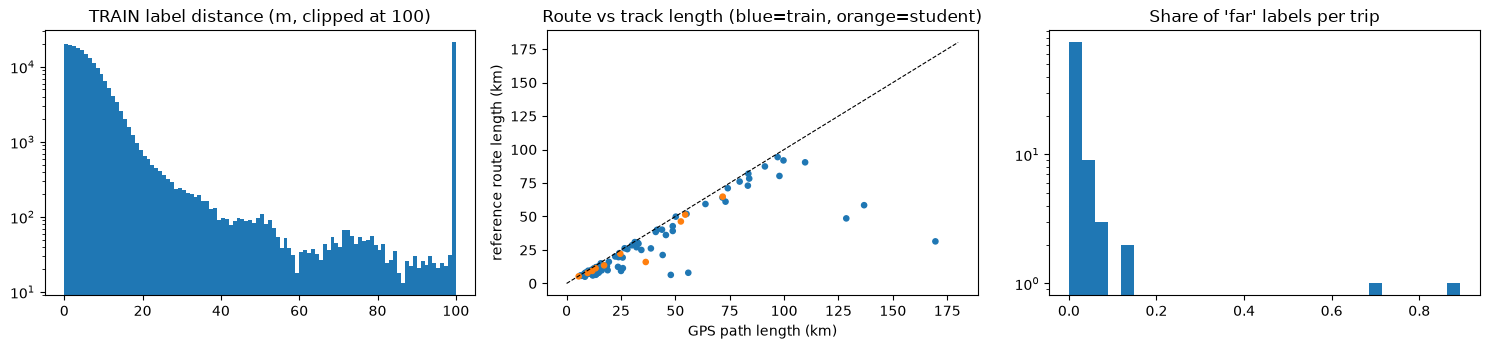

In [10]:
"""Where is the label 'far'? Trips whose reference route covers only part of the GPS track (reference-route limitation)."""
bad = V[V.share_far > .05].sort_values("share_far", ascending=False)
display(bad[["split", "trip_id", "n_points", "route_len", "share_far", "dist_mean", "route_len_m", "track_len_m", "route_to_track_len"]].round(3))
print("trips with >5%% far labels: %d ; trips with route shorter than 60%% of track length: %d" % (len(bad), int((V.route_to_track_len < .6).sum())))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(lab["train"].label_distance_m.clip(upper=100), bins=100); ax[0].set_yscale("log"); ax[0].set_title("TRAIN label distance (m, clipped at 100)")
ax[1].scatter(V.track_len_m / 1e3, V.route_len_m / 1e3, c=(V.split == "train").map({True: "C0", False: "C1"}), s=14); ax[1].plot([0, 180], [0, 180], "k--", lw=.8)
ax[1].set_xlabel("GPS path length (km)"); ax[1].set_ylabel("reference route length (km)"); ax[1].set_title("Route vs track length (blue=train, orange=student)")
ax[2].hist(V.share_far, bins=30); ax[2].set_yscale("log"); ax[2].set_title("Share of 'far' labels per trip"); plt.tight_layout()
(VAL / "figures").mkdir(exist_ok=True); plt.savefig(VAL / "figures" / "label_validation.png", dpi=130); plt.show()

In [11]:
"""Small sensitivity check of the aligner settings on TRAINING trips only (nothing is tuned on student_test)."""
sample = SPLITS["train"][::8][:10]                                    # deterministic 10-trip subset of the training trips
grid = [dict(align_sigma_m=s, align_advance_cost=a) for s in (5.0, 10.0, 15.0) for a in (0.5, 1.0, 2.0)]
srows = []
for g in grid:
    cfg = dict(CONFIG, **g); dm, rec, far = [], [], []
    for tid in sample:
        tr = trips[("train", tid)]; route = P.load_route(DATA, "train", tid, tr.n_arcs)
        L = P.align_to_route(tr, route, flags["train"][flags["train"].trip_id == tid].reset_index(drop=True), cfg)
        dm.append(L.label_distance_m.median()); rec.append(len(np.unique(L.route_pos)) / len(route)); far.append((L.label_quality == "far").mean())
    srows.append(dict(**g, median_label_dist_m=np.mean(dm), recovered_share=np.mean(rec), far_share=np.mean(far)))
sens = pd.DataFrame(srows); sens.to_csv(VAL / "aligner_sensitivity_train.csv", index=False); display(sens.round(3))

,align_sigma_m,align_advance_cost,median_label_dist_m,recovered_share,far_share
0,5.0,0.5,4.864,0.954,0.010
1,5.0,1.0,4.862,0.952,0.010
2,5.0,2.0,4.854,0.943,0.010
3,10.0,0.5,4.934,0.961,0.010
4,10.0,1.0,4.943,0.956,0.010
5,10.0,2.0,4.910,0.943,0.010
6,15.0,0.5,4.976,0.961,0.010
7,15.0,1.0,4.991,0.954,0.010
8,15.0,2.0,4.997,0.935,0.011


In [12]:
"""Save per-point labels (train + student_test) with quality tags; candidates and features are added in 4.4+."""
for s, name in [("train", "point_labels_train"), ("student_test", "point_labels_student")]:
    lab[s].to_parquet(OUTD / f"{name}.parquet", index=False)
P.save_config(CONFIG, HERE / "preprocessing_config.json")
print({s: lab[s].shape for s in lab})

{'train': (208417, 10), 'student_test': (19160, 10)}


### Findings and decision

- Aligner output is monotone for all 90 trips. Mean share of route positions recovered: 96.8% (train) / 96.7% (student); 43/80 train and 4/10 student trips recover >= 99%. Skipped positions are rare (1,027 in train, 111 in student): arcs jumped over in one 1 s step, mostly short arcs.
- Label distance (all train points): median 5.7 m, p95 146 m, max 1,930 m; but the typical trip is much tighter (median trip p95 14.4 m). The long tail comes from a few trips (below).
- Label quality (point-weighted): train clean 80.9% / ambiguous 6.7% / far 12.4%; student clean 81.9% / ambiguous 17.3% / far 0.8%.
- Agreement with the nearest route arc on clean points: 95.3% (train) / 93.8% (student).
- **Reference-route limitation:** 7 train trips have > 5% far labels and 18 trips have a route shorter than 60% of the GPS path. Worst: 00000054 (route 31 km vs track 170 km, 89% far), 00000033 (71% far), 00000002 (14%). The reference route does not cover the whole track, so far points have no valid reference arc. They are tagged `far` and must not be counted as classifier errors without a decision (see open issues).
- Sensitivity (train only, 10 trips): sigma 5/10/15 m and advance cost 0.5/1/2 change the median label distance by < 0.15 m and recovery by < 2.6 points, so labels are not sensitive to these settings. Settings kept: sigma 10 m, advance 1.0.

### Folium sanity map (one train trip): GPS, reference route and aligned labels

In [13]:
"""Map of one train trip: GPS fixes (blue), reference route (green), points whose aligned arc is 'far' (red)."""
tid = SPLITS["train"][0]; tr = trips[("train", tid)]; route = P.load_route(DATA, "train", tid, tr.n_arcs)
inv_tf = Transformer.from_crs(tr.epsg, 4326, always_xy=True)
L = lab["train"][lab["train"].trip_id == tid]
m = folium.Map(location=[tr.gps_lonlat[:, 1].mean(), tr.gps_lonlat[:, 0].mean()], zoom_start=13, tiles="OpenStreetMap")
fg_route = folium.FeatureGroup("Reference route (green)"); fg_gps = folium.FeatureGroup("GPS fixes (blue)"); fg_far = folium.FeatureGroup("Far labels (red)")
for a in route:
    (lo1, la1), (lo2, la2) = inv_tf.transform(*tr.arc_a[a]), inv_tf.transform(*tr.arc_b[a])
    folium.PolyLine([(la1, lo1), (la2, lo2)], color="green", weight=4).add_to(fg_route)
for r in L.itertuples():
    lo, la = tr.gps_lonlat[r.gps_row]; far = r.label_quality == "far"
    folium.CircleMarker((la, lo), radius=2, color="red" if far else "blue", fill=True).add_to(fg_far if far else fg_gps)
for fg in (fg_route, fg_gps, fg_far): fg.add_to(m)
folium.LayerControl().add_to(m); m.save(VAL / f"sanity_map_train_{tid}.html"); m

### Findings and decision

- The map shows GPS fixes (blue), the reference route (green) and far labels (red) with a layer control. Saved as an HTML file in `cleaned_data/validation/`.